In [1]:
import pandas as pd
import numpy as np

In [7]:
df=pd.read_csv('Ecommerce_data.csv')
df['Date']

0       2023-01-01
1       2023-01-01
2       2023-01-01
3       2023-01-01
4       2023-01-01
           ...    
4995    2024-03-26
4996    2024-03-26
4997    2024-03-26
4998    2024-03-26
4999    2024-03-26
Name: Date, Length: 5000, dtype: object

In [39]:
df['Date']=pd.to_datetime(df['Date'])
df['Day'] = df['Date'].dt.day
df.head()
df['durection_time'] = df['Delivery_Time_Days'] -df['Day']
df['Year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month

df.head()
df['Day'].mean()
df.set_index('Date')

,Order_ID,Customer_ID,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,...,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating,Day,durection_time,Year,month
Date,,,,,,,,,,,,,,,,,,,,,
2023-01-01,ORD_001337,CUST_01337,27,Female,Bursa,Toys,54.28,1,0.00,54.28,...,Mobile,4,14,True,8,5,1,7,2023,1
2023-01-01,ORD_004885,CUST_04885,42,Male,Konya,Toys,244.90,1,0.00,244.90,...,Mobile,11,3,True,3,3,1,2,2023,1
2023-01-01,ORD_004507,CUST_04507,43,Female,Ankara,Food,48.15,5,0.00,240.75,...,Mobile,7,8,True,5,2,1,4,2023,1
2023-01-01,ORD_000645,CUST_00645,32,Male,Istanbul,Electronics,804.06,1,229.28,574.78,...,Mobile,8,10,False,1,4,1,0,2023,1
2023-01-01,ORD_000690,CUST_00690,40,Female,Istanbul,Sports,755.61,5,0.00,3778.05,...,Desktop,21,10,True,7,4,1,6,2023,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-03-26,ORD_001048,CUST_01048,18,Female,Izmir,Beauty,130.35,1,27.30,103.05,...,Mobile,17,10,False,9,1,26,-17,2024,3
2024-03-26,ORD_001051,CUST_01051,27,Male,Adana,Beauty,71.55,1,0.00,71.55,...,Mobile,13,9,True,6,4,26,-20,2024,3
2024-03-26,ORD_003543,CUST_03543,45,Female,Antalya,Food,39.38,1,5.27,34.11,...,Mobile,38,10,True,5,4,26,-21,2024,3


<Axes: >

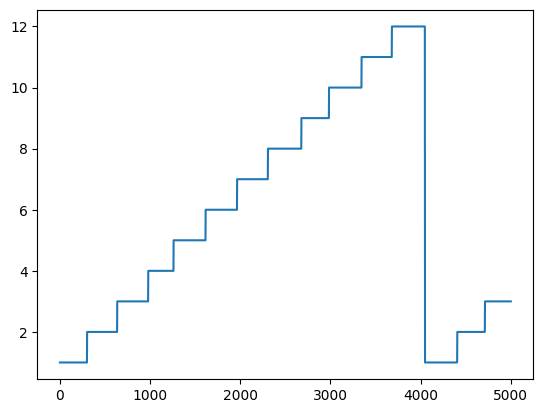

In [44]:
df['month'].plot()

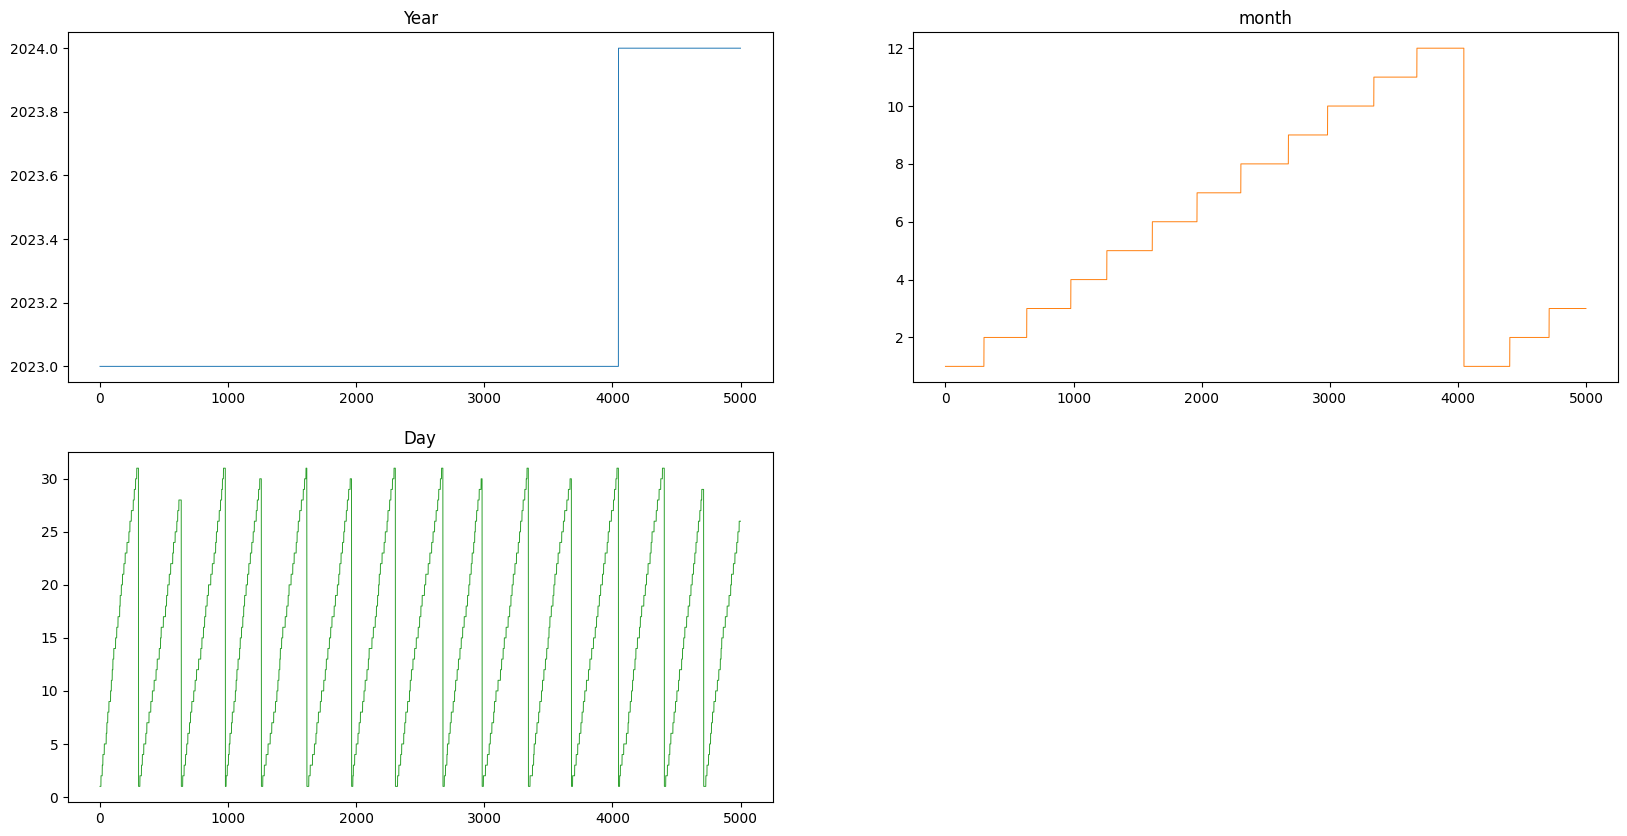

In [50]:
# viz all cols together
subset_yt = df[['Year', 'month', 'Day']]
ax = subset_yt.plot(subplots=True,
                    layout=(2, 2),
                     sharex=False,
                     sharey=False,
                     linewidth=0.7,
                     fontsize=10,
                     legend=False,
                      figsize=(20,10),
                      title=['Year', 'month', 'Day'])

In [ ]:
# df['year'].plot()
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Order_ID                  5000 non-null   object        
 1   Customer_ID               5000 non-null   object        
 2   Date                      5000 non-null   datetime64[ns]
 3   Age                       5000 non-null   int64         
 4   Gender                    5000 non-null   object        
 5   City                      5000 non-null   object        
 6   Product_Category          5000 non-null   object        
 7   Unit_Price                5000 non-null   float64       
 8   Quantity                  5000 non-null   int64         
 9   Discount_Amount           5000 non-null   float64       
 10  Total_Amount              5000 non-null   float64       
 11  Payment_Method            5000 non-null   object        
 12  Device_Type         

In [30]:
df[df['Date'] == '2023'][['City','Product_Category','Quantity','Total_Amount']].agg['Total_Amount:sum']

,City,Product_Category,Quantity,Total_Amount
0,Bursa,Toys,1,54.28
1,Konya,Toys,1,244.9
2,Ankara,Food,5,240.75
3,Istanbul,Electronics,1,574.78
4,Istanbul,Sports,5,3778.05
5,Istanbul,Beauty,1,122.46
6,Izmir,Electronics,2,4214.74
7,Konya,Food,2,427.28


In [34]:
df[df['Date']=='2023'].groupby(
    ['City', 'Product_Category']
)['Total_Amount'].sum()

City      Product_Category
Ankara    Food                 240.75
Bursa     Toys                  54.28
Istanbul  Beauty               122.46
          Electronics          574.78
          Sports              3778.05
Izmir     Electronics         4214.74
Konya     Food                 427.28
          Toys                 244.90
Name: Total_Amount, dtype: float64